In [21]:
# =========================
# EX2.ipynb TEMPLATE (FULL)
# =========================
# Paste these cells in order. No external deps needed.

# -------------------------
# CELL 1 — Imports + .env + Config
# -------------------------
import os
import re
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, Tuple, List, Optional

import numpy as np
import cv2


def load_env_file(dotenv_path: Path, override: bool = True) -> None:
    if not dotenv_path.exists():
        print("[ENV] .env not found at:", dotenv_path)
        return
    print("[ENV] loading:", dotenv_path)
    for line in dotenv_path.read_text(encoding="utf-8", errors="ignore").splitlines():
        s = line.strip()
        if not s or s.startswith("#") or "=" not in s:
            continue
        k, v = s.split("=", 1)
        k = k.strip()
        v = v.strip().strip('"').strip("'")
        if not override and k in os.environ:
            continue
        os.environ[k] = v


def _get_tuple_int_env(name: str, default: str = "") -> Optional[Tuple[int, int, int, int]]:
    val = os.getenv(name, default).strip()
    if not val:
        return None
    parts = [p.strip() for p in val.split(",")]
    if len(parts) != 4:
        return None
    return tuple(map(int, parts))


@dataclass
class Ex2Config:
    ex2_dir: Path
    train_dir: Path
    test_dir: Path
    out_dir: Path

    ann1_suffix: str = "_1.txt"
    ann2_suffix: str = "_2.txt"

    warp_size: int = 800
    grid_n: int = 4
    cell_inner_margin: float = 0.10

    tmpl_size: int = 48
    bin_inv: bool = True

    # Occupancy detection
    occ_mode: str = "template"   # "template" or "ink"
    occ_margin: float = 0.02     # for template mode (non-s must beat s by this margin)
    occ_ink_thr: float = 0.0     # for ink mode (0 = auto from training)

    # Numbering scheme: we will AUTO-CHOOSE between spiral and row_major on train
    manual_roi: Optional[Tuple[int, int, int, int]] = None
    debug: int = 1


print("CWD:", Path.cwd())
load_env_file(Path.cwd() / ".env", override=True)

EX2_DIR = Path(os.getenv("EX2_DIR", "Lucrare1/data/ex2"))

CFG = Ex2Config(
    ex2_dir=EX2_DIR,
    train_dir=Path(os.getenv("EX2_TRAIN_DIR", str(EX2_DIR / "antrenare"))),
    test_dir=Path(os.getenv("EX2_TEST_DIR", str(EX2_DIR / "testare"))),
    out_dir=Path(os.getenv("EX2_OUT_DIR", "outputs/ex2")),

    ann1_suffix=os.getenv("EX2_ANN1_SUFFIX", "_1.txt"),
    ann2_suffix=os.getenv("EX2_ANN2_SUFFIX", "_2.txt"),

    warp_size=int(os.getenv("EX2_WARP_SIZE", "800")),
    grid_n=int(os.getenv("EX2_GRID_N", "4")),
    cell_inner_margin=float(os.getenv("EX2_CELL_MARGIN", "0.10")),

    tmpl_size=int(os.getenv("EX2_TMPL_SIZE", "48")),
    bin_inv=os.getenv("EX2_BIN_INV", "1") == "1",

    occ_mode=os.getenv("EX2_OCC_MODE", "template").strip().lower(),
    occ_margin=float(os.getenv("EX2_OCC_MARGIN", "0.02")),
    occ_ink_thr=float(os.getenv("EX2_OCC_INK_THR", "0")),

    manual_roi=_get_tuple_int_env("EX2_MANUAL_ROI"),
    debug=int(os.getenv("EX2_DEBUG", "1")),
)

CFG.out_dir.mkdir(parents=True, exist_ok=True)

print("CFG:", CFG)
print("train exists:", CFG.train_dir.exists(), "test exists:", CFG.test_dir.exists())


CWD: c:\Users\drago\Desktop\Lucrare1
[ENV] loading: c:\Users\drago\Desktop\Lucrare1\.env
CFG: Ex2Config(ex2_dir=WindowsPath('Lucrare1/data/ex2'), train_dir=WindowsPath('Lucrare1/data/ex2/antrenare'), test_dir=WindowsPath('Lucrare1/data/ex2/testare'), out_dir=WindowsPath('outputs/ex2'), ann1_suffix='_1.txt', ann2_suffix='_2.txt', warp_size=100, grid_n=4, cell_inner_margin=0.05, tmpl_size=64, bin_inv=True, occ_mode='template', occ_margin=0.02, occ_ink_thr=0.0, manual_roi=None, debug=1)
train exists: True test exists: True


In [22]:
# -------------------------
# CELL 2 — File listing + label parsing
# -------------------------
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def list_images(folder: Path) -> List[Path]:
    if not folder.exists():
        return []
    out = []
    for p in folder.rglob("*"):
        sp = str(p).lower()
        if "__macosx" in sp:
            continue
        if p.name.startswith("._"):
            continue
        if p.is_file() and p.suffix.lower() in IMG_EXTS:
            out.append(p)
    return sorted(out)

def ann_paths_for(img_path: Path) -> Tuple[Path, Path]:
    stem = img_path.stem
    a1 = img_path.with_name(stem + CFG.ann1_suffix)
    a2 = img_path.with_name(stem + CFG.ann2_suffix)
    return a1, a2

def parse_kv_txt(path: Path) -> Dict[int, str]:
    """
    Format: <square_number> <value>
      stage1: value in {'o','s'}
      stage2: value in {'0'..'9','+','-','=','s','O',...} (keep exact)
    """
    d: Dict[int, str] = {}
    if not path.exists():
        return d
    for line in path.read_text(encoding="utf-8", errors="ignore").splitlines():
        s = line.strip()
        if not s:
            continue
        parts = re.split(r"\s+", s)
        if len(parts) < 2:
            continue
        try:
            k = int(parts[0])
        except Exception:
            continue
        d[k] = parts[1]
    return d

train_imgs = list_images(CFG.train_dir)
test_imgs = list_images(CFG.test_dir)

print("Train images:", len(train_imgs))
print("Test images:", len(test_imgs))
if len(train_imgs) == 0:
    raise FileNotFoundError(f"No training images found in {CFG.train_dir.resolve()}")


Train images: 10
Test images: 0


In [23]:
# -------------------------
# CELL 3 — Numbering maps + board warp + cell extraction
# -------------------------
def spiral_map_4x4() -> np.ndarray:
    # 1..16 spiral clockwise from top-left
    return np.array([
        [ 1,  2,  3,  4],
        [12, 13, 14,  5],
        [11, 16, 15,  6],
        [10,  9,  8,  7],
    ], dtype=np.int32)

def row_major_map_4x4() -> np.ndarray:
    return np.array([
        [ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12],
        [13, 14, 15, 16],
    ], dtype=np.int32)

def get_number_map(n: int, scheme: str) -> np.ndarray:
    if n != 4:
        raise ValueError("This template assumes 4x4 grid. If exam changes grid_n, adapt numbering.")
    if scheme == "row_major":
        return row_major_map_4x4()
    if scheme == "spiral":
        return spiral_map_4x4()
    raise ValueError("scheme must be 'spiral' or 'row_major'")

def order_points(pts: np.ndarray) -> np.ndarray:
    rect = np.zeros((4,2), dtype=np.float32)
    s = pts.sum(axis=1)
    rect[0] = pts[np.argmin(s)]
    rect[2] = pts[np.argmax(s)]
    diff = np.diff(pts, axis=1).reshape(-1)
    rect[1] = pts[np.argmin(diff)]
    rect[3] = pts[np.argmax(diff)]
    return rect

def find_board_quad(img_bgr: np.ndarray) -> Optional[np.ndarray]:
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    thr = cv2.adaptiveThreshold(
        gray, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        31, 5
    )
    thr = cv2.morphologyEx(thr, cv2.MORPH_CLOSE, np.ones((5,5), np.uint8), iterations=2)

    cnts, _ = cv2.findContours(thr, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return None

    cnts = sorted(cnts, key=cv2.contourArea, reverse=True)

    for c in cnts[:10]:
        peri = cv2.arcLength(c, True)
        approx = cv2.approxPolyDP(c, 0.02 * peri, True)
        if len(approx) == 4:
            return approx.reshape(4,2).astype(np.float32)

    # fallback: minAreaRect
    c = cnts[0]
    rect = cv2.minAreaRect(c)
    box = cv2.boxPoints(rect).astype(np.float32)
    return box


def warp_board(img_bgr: np.ndarray) -> np.ndarray:
    if CFG.manual_roi is not None:
        x1,y1,x2,y2 = CFG.manual_roi
        img_bgr = img_bgr[y1:y2, x1:x2].copy()

    quad = find_board_quad(img_bgr)
    if quad is None:
        h,w = img_bgr.shape[:2]
        s = int(min(h,w)*0.85)
        x1 = (w - s)//2
        y1 = (h - s)//2
        crop = img_bgr[y1:y1+s, x1:x1+s]
        return cv2.resize(crop, (CFG.warp_size, CFG.warp_size), interpolation=cv2.INTER_AREA)

    rect = order_points(quad)
    dst = np.array([
        [0, 0],
        [CFG.warp_size-1, 0],
        [CFG.warp_size-1, CFG.warp_size-1],
        [0, CFG.warp_size-1],
    ], dtype=np.float32)
    M = cv2.getPerspectiveTransform(rect, dst)
    return cv2.warpPerspective(img_bgr, M, (CFG.warp_size, CFG.warp_size))

def extract_cells(warped_bgr: np.ndarray, num_map: np.ndarray) -> Dict[int, np.ndarray]:
    n = CFG.grid_n
    s = CFG.warp_size
    cell = s // n
    m = int(cell * CFG.cell_inner_margin)

    out: Dict[int, np.ndarray] = {}
    for r in range(n):
        for c in range(n):
            y1 = r*cell + m
            y2 = (r+1)*cell - m
            x1 = c*cell + m
            x2 = (c+1)*cell - m
            roi = warped_bgr[y1:y2, x1:x2]
            sq_num = int(num_map[r, c])
            out[sq_num] = roi
    return out


In [24]:
# -------------------------
# CELL 4 — Preprocessing + similarity + helpers
# -------------------------
def preprocess_cell(cell_bgr: np.ndarray) -> np.ndarray:
    gray = cv2.cvtColor(cell_bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (3,3), 0)

    thr_type = cv2.THRESH_BINARY_INV if CFG.bin_inv else cv2.THRESH_BINARY
    _, bw = cv2.threshold(gray, 0, 255, thr_type | cv2.THRESH_OTSU)

    bw = cv2.morphologyEx(bw, cv2.MORPH_OPEN, np.ones((2,2), np.uint8), iterations=1)
    bw = cv2.resize(bw, (CFG.tmpl_size, CFG.tmpl_size), interpolation=cv2.INTER_AREA)
    return (bw.astype(np.float32) / 255.0)

def ink_ratio(x: np.ndarray) -> float:
    return float(np.mean(x > 0.5))

def cosine_sim(a: np.ndarray, b: np.ndarray) -> float:
    va = a.reshape(-1)
    vb = b.reshape(-1)
    na = np.linalg.norm(va) + 1e-8
    nb = np.linalg.norm(vb) + 1e-8
    return float(np.dot(va, vb) / (na * nb))

def exact_match(d_pred: Dict[int,str], d_gt: Dict[int,str]) -> bool:
    for k in range(1, 17):
        if str(d_pred.get(k, "")) != str(d_gt.get(k, "")):
            return False
    return True


In [25]:
# -------------------------
# CELL 5 — Build templates FOR A GIVEN NUMBERING SCHEME
# -------------------------
def build_templates_for_scheme(scheme: str):
    num_map = get_number_map(CFG.grid_n, scheme)

    templates: Dict[str, List[np.ndarray]] = {}
    ink_empty, ink_full = [], []

    for img_path in train_imgs:
        a1, a2 = ann_paths_for(img_path)
        gt2 = parse_kv_txt(a2)  # stage2

        img = cv2.imread(str(img_path), cv2.IMREAD_COLOR)
        if img is None:
            raise FileNotFoundError(f"Cannot read {img_path}")

        warped = warp_board(img)
        cells = extract_cells(warped, num_map)

        for k, cell_bgr in cells.items():
            x = preprocess_cell(cell_bgr)
            lab2 = gt2.get(k, "s")  # default to empty if missing
            templates.setdefault(lab2, []).append(x)

            ir = ink_ratio(x)
            if lab2 == "s":
                ink_empty.append(ir)
            else:
                ink_full.append(ir)

    # auto ink threshold if needed
    occ_thr = CFG.occ_ink_thr
    if occ_thr <= 0.0:
        if len(ink_empty) == 0 or len(ink_full) == 0:
            occ_thr = 0.02
        else:
            occ_thr = (float(np.median(ink_empty)) + float(np.median(ink_full))) / 2.0

    return num_map, templates, occ_thr

def best_match_over_labels(x: np.ndarray, templates: Dict[str, List[np.ndarray]], labels: List[str]) -> Tuple[str, float]:
    best_lab, best_sc = None, -1.0
    for lab in labels:
        for t in templates.get(lab, []):
            sc = cosine_sim(x, t)
            if sc > best_sc:
                best_sc = sc
                best_lab = lab
    return (best_lab if best_lab is not None else "s"), best_sc


In [26]:
# -------------------------
# CELL 6 — Predict + Evaluate FOR A GIVEN SCHEME
# -------------------------
def predict_image(img_path: Path, num_map: np.ndarray, templates: Dict[str, List[np.ndarray]], occ_thr: float):
    img = cv2.imread(str(img_path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Cannot read {img_path}")

    warped = warp_board(img)
    cells = extract_cells(warped, num_map)

    labels_all = list(templates.keys())
    non_s_labels = [k for k in labels_all if k != "s"]

    pred1: Dict[int, str] = {}
    pred2: Dict[int, str] = {}

    for k in sorted(cells.keys()):
        x = preprocess_cell(cells[k])

        if CFG.occ_mode == "template":
            _, sc_s = best_match_over_labels(x, templates, ["s"])
            lab_ns, sc_ns = best_match_over_labels(x, templates, non_s_labels)

            occ = (sc_ns > sc_s + CFG.occ_margin)
            pred1[k] = "o" if occ else "s"
            pred2[k] = lab_ns if occ else "s"
        else:
            ir = ink_ratio(x)
            occ = (ir >= occ_thr)
            pred1[k] = "o" if occ else "s"
            pred2[k] = best_match_over_labels(x, templates, non_s_labels)[0] if occ else "s"

        # hard consistency
        if pred1[k] == "s":
            pred2[k] = "s"

    return pred1, pred2

def evaluate_scheme(scheme: str):
    num_map, templates, occ_thr = build_templates_for_scheme(scheme)

    ok1 = ok2 = okb = 0
    for img_path in train_imgs:
        a1, a2 = ann_paths_for(img_path)
        gt1 = parse_kv_txt(a1)
        gt2 = parse_kv_txt(a2)

        p1, p2 = predict_image(img_path, num_map, templates, occ_thr)

        m1 = exact_match(p1, gt1)
        m2 = exact_match(p2, gt2)
        ok1 += int(m1)
        ok2 += int(m2)
        okb += int(m1 and m2)

        if CFG.debug and not (m1 and m2):
            print("[MISS]", scheme, img_path.name, "stage1:", m1, "stage2:", m2)

    return ok1, ok2, okb, num_map, templates, occ_thr


In [31]:
# -------------------------
# CELL 7 — Auto-choose scheme + cell margin (robust)
# -------------------------

MARGIN_CANDS = [0.05, 0.08, 0.10, 0.12, 0.15]  # you can tweak list if needed

def evaluate_combo(scheme: str, margin: float):
    old_margin = CFG.cell_inner_margin
    CFG.cell_inner_margin = float(margin)
    try:
        ok1, ok2, okb, num_map, templates, occ_thr = evaluate_scheme(scheme)
        return ok1, ok2, okb, num_map, templates, occ_thr
    finally:
        CFG.cell_inner_margin = old_margin

results = {}
for scheme in ["row_major", "spiral"]:
    for m in MARGIN_CANDS:
        ok1, ok2, okb, num_map, templates, occ_thr = evaluate_combo(scheme, m)
        results[(scheme, m)] = (ok1, ok2, okb, num_map, templates, occ_thr)
        print(f"[{scheme} | margin={m:.2f}] stage1={ok1}/{len(train_imgs)} stage2={ok2}/{len(train_imgs)} both={okb}/{len(train_imgs)}")

def score(t):
    ok1, ok2, okb = t[0], t[1], t[2]
    return (okb, ok2, ok1)

(best_scheme, best_margin) = max(results.keys(), key=lambda k: score(results[k]))
ok1, ok2, okb, NUM_MAP, TEMPLATES, OCC_THR = results[(best_scheme, best_margin)]

# lock chosen margin for later extraction/writing
CFG.cell_inner_margin = float(best_margin)

print("\nBEST:", best_scheme, "margin=", best_margin)
print("Final train:", f"stage1={ok1}/{len(train_imgs)} stage2={ok2}/{len(train_imgs)} both={okb}/{len(train_imgs)}")
print("Occupancy mode:", CFG.occ_mode, "occ_thr(ink):", OCC_THR, "occ_margin(template):", CFG.occ_margin)


[MISS] row_major 003.jpg stage1: False stage2: False
[row_major | margin=0.05] stage1=9/10 stage2=9/10 both=9/10
[MISS] row_major 003.jpg stage1: False stage2: False
[MISS] row_major 006.jpg stage1: False stage2: False
[MISS] row_major 007.jpg stage1: False stage2: False
[MISS] row_major 008.jpg stage1: False stage2: False
[row_major | margin=0.08] stage1=6/10 stage2=6/10 both=6/10
[MISS] row_major 003.jpg stage1: False stage2: False
[MISS] row_major 006.jpg stage1: False stage2: False
[MISS] row_major 007.jpg stage1: False stage2: False
[MISS] row_major 008.jpg stage1: False stage2: False
[row_major | margin=0.10] stage1=6/10 stage2=6/10 both=6/10
[MISS] row_major 006.jpg stage1: False stage2: False
[row_major | margin=0.12] stage1=9/10 stage2=9/10 both=9/10
[MISS] row_major 006.jpg stage1: False stage2: False
[row_major | margin=0.15] stage1=9/10 stage2=9/10 both=9/10
[MISS] spiral 003.jpg stage1: False stage2: False
[MISS] spiral 004.jpg stage1: False stage2: False
[MISS] spiral 008

IMAGE: 001.jpg scheme: row_major
bad stage1 cells: []
bad stage2 cells: []


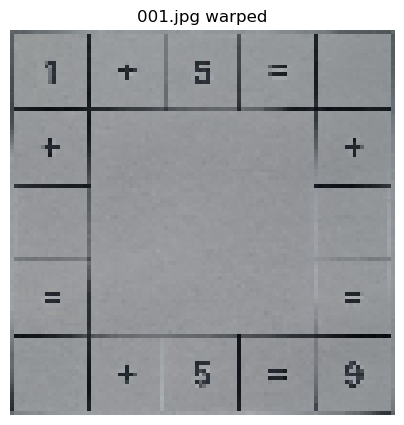

IMAGE: 004.jpg scheme: row_major
bad stage1 cells: []
bad stage2 cells: []


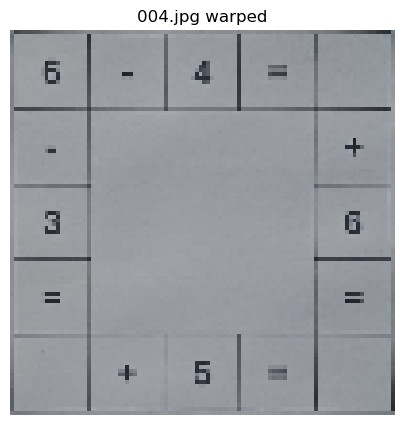

IMAGE: 005.jpg scheme: row_major
bad stage1 cells: []
bad stage2 cells: []


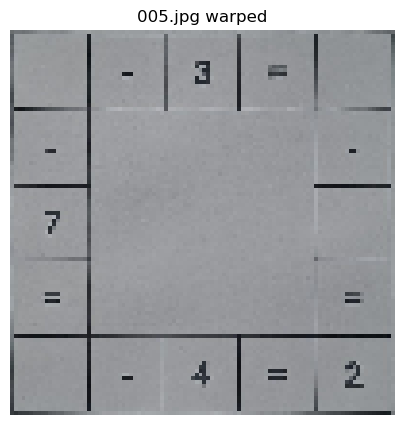

In [28]:
import matplotlib.pyplot as plt

def diff_keys(d_pred: Dict[int,str], d_gt: Dict[int,str]) -> List[int]:
    bad = []
    for k in range(1, 17):
        if str(d_pred.get(k, "")) != str(d_gt.get(k, "")):
            bad.append(k)
    return bad

def report_miss(img_name: str, scheme: str = None):
    scheme = scheme or best_scheme
    img_path = CFG.train_dir / img_name
    if not img_path.exists():
        raise FileNotFoundError(img_path)

    # rebuild templates/num_map for this scheme
    num_map, templates, occ_thr = build_templates_for_scheme(scheme)

    a1, a2 = ann_paths_for(img_path)
    gt1 = parse_kv_txt(a1)
    gt2 = parse_kv_txt(a2)

    p1, p2 = predict_image(img_path, num_map, templates, occ_thr)

    b1 = diff_keys(p1, gt1)
    b2 = diff_keys(p2, gt2)
    print("IMAGE:", img_name, "scheme:", scheme)
    print("bad stage1 cells:", b1)
    print("bad stage2 cells:", b2)

    img = cv2.imread(str(img_path), cv2.IMREAD_COLOR)
    warped = warp_board(img)
    cells = extract_cells(warped, num_map)

    # show warped board (quick)
    plt.figure(figsize=(5,5))
    plt.title(f"{img_name} warped")
    plt.imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

    # show only the cells that differ
    for k in sorted(set(b1 + b2)):
        x = preprocess_cell(cells[k])
        plt.figure(figsize=(3,3))
        plt.title(f"cell {k}  gt1={gt1.get(k)} pred1={p1[k]} | gt2={gt2.get(k)} pred2={p2[k]}")
        plt.imshow(x, cmap="gray")
        plt.axis("off")
        plt.show()

# run on your misses
report_miss("001.jpg")
report_miss("004.jpg")
report_miss("005.jpg")


In [29]:
# -------------------------
# CELL 8 — Write outputs for test set
# -------------------------
CFG.out_dir.mkdir(parents=True, exist_ok=True)
print("Output dir:", CFG.out_dir.resolve())

def write_stage_files(img_path: Path, pred1: Dict[int,str], pred2: Dict[int,str]) -> None:
    stem = img_path.stem
    out1 = CFG.out_dir / f"{stem}{CFG.ann1_suffix}"
    out2 = CFG.out_dir / f"{stem}{CFG.ann2_suffix}"

    with out1.open("w", encoding="utf-8") as f:
        for k in range(1, 17):
            f.write(f"{k} {pred1[k]}\n")

    with out2.open("w", encoding="utf-8") as f:
        for k in range(1, 17):
            f.write(f"{k} {pred2[k]}\n")

if len(test_imgs) == 0:
    print("[INFO] No test images found (ok).")
else:
    for img_path in test_imgs:
        p1, p2 = predict_image(img_path, NUM_MAP, TEMPLATES, OCC_THR)
        write_stage_files(img_path, p1, p2)
    print("[DONE] wrote", len(test_imgs), "pairs of files.")


Output dir: C:\Users\drago\Desktop\Lucrare1\outputs\ex2
[INFO] No test images found (ok).


In [30]:
test_imgs = list_images(CFG.test_dir)
print("Test images:", len(test_imgs))
print("Output dir:", CFG.out_dir.resolve())

def write_stage_files(img_path: Path, pred1: Dict[int,str], pred2: Dict[int,str]) -> None:
    stem = img_path.stem
    out1 = CFG.out_dir / f"{stem}{CFG.ann1_suffix}"
    out2 = CFG.out_dir / f"{stem}{CFG.ann2_suffix}"

    # IMPORTANT: write lines ordered by square number 1..16
    with out1.open("w", encoding="utf-8") as f:
        for k in range(1, 17):
            f.write(f"{k} {pred1[k]}\n")

    with out2.open("w", encoding="utf-8") as f:
        for k in range(1, 17):
            f.write(f"{k} {pred2[k]}\n")

if len(test_imgs) == 0:
    print("[INFO] No test images yet (normal before lab).")
else:
    for img_path in test_imgs:
        p1, p2 = predict_image(img_path)
        write_stage_files(img_path, p1, p2)

    print("[DONE] wrote", len(test_imgs), "pairs of files.")


Test images: 0
Output dir: C:\Users\drago\Desktop\Lucrare1\outputs\ex2
[INFO] No test images yet (normal before lab).
